# 🎯 Регуляризація: Ridge і LASSO · Traceback і assert

**Заняття з машинного навчання**

Тривалість: **90 хвилин** · Інструменти: `numpy`, `pandas`, `matplotlib`, `scikit-learn`

| # | Тема | Час |
|---|---|---|
| 0 | Вступ: що ми вже вміємо | 3 хв |
| | **Частина 1. Регуляризація** | |
| 1 | Проблема: забагато ознак і перенавчання | 12 хв |
| 2 | Ідея регуляризації: штраф за великі коефіцієнти | 8 хв |
| 3 | Масштабування ознак — обов'язковий крок | 7 хв |
| 4 | Ridge-регресія (L2) | 12 хв |
| 5 | LASSO-регресія (L1) | 10 хв |
| 6 | Як обрати силу штрафу α | 8 хв |
| 7 | Ridge проти LASSO: порівняння та інтерпретація | 10 хв |
| | **Частина 2. Помилки в коді** | |
| 8 | Як читати traceback; типи помилок | 9 хв |
| 9 | `assert` і навіщо він потрібен | 8 хв |
| 10 | Підсумок | 3 хв |
| ✍️ | Перевірте себе (домашнє завдання) | — |

> 💡 Ноутбук можна відкрити в **Google Colab**: *File → Upload notebook*. Усі дані генеруються всередині ноутбука. Щоб пройти все з нуля: *Runtime → Run all*.

---
## 0. Вступ (⏱ 3 хв)

Ми вже вміємо будувати **лінійну регресію з кількома ознаками**:

$$\hat{y} = a + b_1 x_1 + b_2 x_2 + \dots + b_p x_p$$

і знаємо головне правило: **оцінювати модель треба на тестових даних**, яких вона не бачила.

Ми також бачили, що модель може **перенавчитися** — «завчити» навчальні дані разом із шумом. Минулого разу причиною була занадто складна крива. Сьогодні подивимось на іншу, дуже поширену на практиці причину: **забагато ознак**. І вивчимо два інструменти, які з цим борються: **Ridge** і **LASSO**.

Наприкінці — 15 хвилин про навичку, що знадобиться щодня: як **читати помилки Python** і як ловити проблеми в даних за допомогою `assert`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.float_format', '{:.3f}'.format)

---
# Частина 1. Регуляризація

## 1. Проблема: забагато ознак і перенавчання (⏱ 12 хв)

### Дані

70 квартир і **32 ознаки**. Ми самі згенерували дані, тому знаємо «правду»:

| Група | Ознаки | Чи впливають на ціну? |
|---|---|---|
| Корисні | `area`, `rooms`, `distance`, `renovation` (стан ремонту 1–5), `building_age` | ✅ так |
| «Майже дублікати» площі | `living_area` (житлова), `kitchen_area` (кухня) | майже повторюють `area` |
| Шум | `noise_01` … `noise_25` — випадкові числа | ❌ ні |

У реальних даних так буває постійно: з бази вивантажують десятки колонок, і заздалегідь невідомо, які з них корисні. Частина — дублікати, частина — просто шум.

In [ ]:
rng = np.random.default_rng(4)
n = 70
area = rng.uniform(30, 120, n)
distance = rng.uniform(1, 15, n)
rooms = np.clip(np.round(area / 28 + rng.normal(0, 0.5, n)), 1, 5)
renovation = rng.integers(1, 6, n)
building_age = rng.uniform(0, 60, n)
living_area = 0.75 * area + rng.normal(0, 2, n)
kitchen_area = 0.12 * area + rng.normal(0, 1.5, n)
price = 12 + 1.0 * area - 2.2 * distance + 2.0 * rooms + 3.0 * renovation - 0.15 * building_age + rng.normal(0, 7, n)

data = {'area': area, 'living_area': living_area, 'kitchen_area': kitchen_area, 'rooms': rooms,
        'distance': distance, 'renovation': renovation, 'building_age': building_age}
for i in range(1, 26):
    data[f'noise_{i:02d}'] = rng.normal(0, 1, n)

X = pd.DataFrame(data).round(2)
y = pd.Series(price.round(1), name='price')
print('X:', X.shape, '| y:', y.shape)
X.iloc[:5, :9]

X: (70, 32) | y: (70,)


,area,living_area,kitchen_area,rooms,distance,renovation,building_age,noise_01,noise_02
0,114.880,86.270,13.470,4.000,4.270,5,10.220,0.830,-1.100
1,76.020,54.000,8.990,2.000,2.100,5,15.050,0.240,-0.810
2,117.860,90.660,13.050,3.000,12.030,1,59.720,-0.600,-1.140
3,37.280,24.870,4.870,1.000,9.700,2,25.020,-0.050,-0.250
4,84.660,64.020,10.370,4.000,4.330,1,38.560,-0.240,-0.320


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(f'Навчальних квартир: {len(X_train)}, ознак: {X_train.shape[1]}')

Навчальних квартир: 49, ознак: 32


👀 **Зверніть увагу:** у навчальній вибірці лише 49 квартир, а ознак — 32. Це майже «по 1.5 квартири на ознаку». Для моделі це небезпечно: вона легко знайде комбінацію з 32 чисел, яка майже ідеально пройде через 49 точок, — навіть використовуючи випадковий шум.

### Звичайна лінійна регресія

In [ ]:
ols = make_pipeline(StandardScaler(), LinearRegression())   # що таке StandardScaler — у розділі 3
ols.fit(X_train, y_train)

print(f'R² на навчальних даних: {r2_score(y_train, ols.predict(X_train)):.3f}')
print(f'R² на тестових даних:   {r2_score(y_test, ols.predict(X_test)):.3f}')
print(f'MAE на тестових даних:  {mean_absolute_error(y_test, ols.predict(X_test)):.2f} тис. $')

R² на навчальних даних: 0.985
R² на тестових даних:   0.825
MAE на тестових даних:  10.32 тис. $


Класична картина **перенавчання**: на навчальних даних модель майже ідеальна (R² ≈ 0.98), а на нових — помітно гірша.

Подивимось на коефіцієнти. Якби модель знайшла «правду», у 25 шумових ознак коефіцієнти були б нульові.

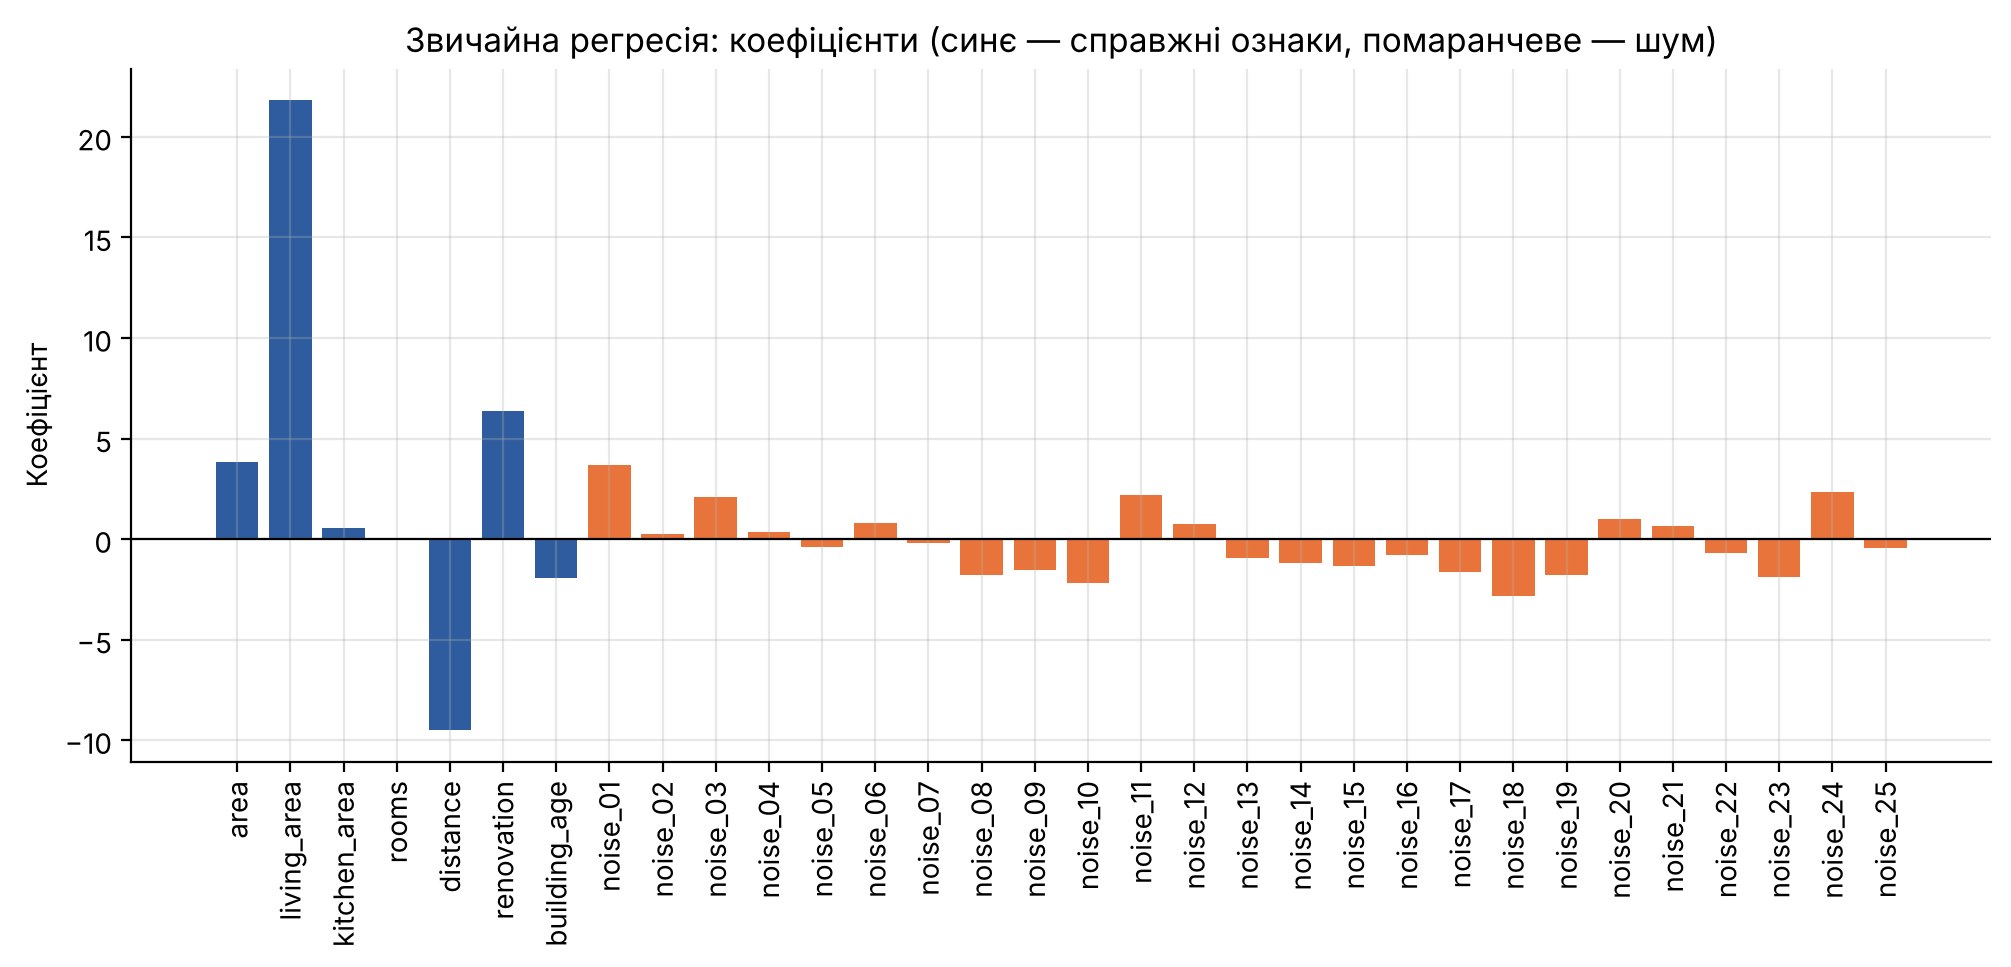

area            3.810
living_area    21.830
kitchen_area    0.560
dtype: float64


In [ ]:
coef_ols = pd.Series(ols[-1].coef_, index=X.columns)
colors = ['#E8743B' if c.startswith('noise') else '#2E5C9E' for c in X.columns]

plt.figure(figsize=(12, 4.5))
plt.bar(X.columns, coef_ols, color=colors)
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=90)
plt.title('Звичайна регресія: коефіцієнти (синє — справжні ознаки, помаранчеве — шум)')
plt.ylabel('Коефіцієнт')
plt.show()

print(coef_ols[['area', 'living_area', 'kitchen_area']].round(2))

**Дві проблеми одразу:**

1. **Шумові ознаки отримали помітні коефіцієнти.** Модель «пояснює» випадковими числами частину навчальних даних — тобто завчила шум.
2. **Площі поводяться дивно.** Ми згенерували ціну так, що вона залежить саме від `area`. Але майже вся «вага» дісталася `living_area` (≈ 21.8), а `area` отримала лише ≈ 3.8. Причина: `area`, `living_area` і `kitchen_area` майже однакові за змістом (сильно корелюють), і модель не може «чесно» розподілити між ними вплив. Розподіл виходить випадковим, а на іншій вибірці може бути зовсім іншим, аж до від'ємних коефіцієнтів. Це явище називають **мультиколінеарністю**. Такі коефіцієнти неможливо інтерпретувати.

Обидві проблеми мають спільний симптом: модель дозволяє собі **занадто великі і довільні коефіцієнти**.

---
## 2. Ідея регуляризації: штраф за великі коефіцієнти (⏱ 8 хв)

Звичайна регресія мінімізує лише помилку:

$$\text{Мінімізуємо:}\quad \text{MSE}$$

**Регуляризація** додає до помилки **штраф** за великі коефіцієнти:

$$\text{Мінімізуємо:}\quad \text{MSE} + \alpha \cdot \text{штраф за коефіцієнти}$$

Тепер модель має компроміс: щоб зменшити помилку, вона хоче великі коефіцієнти, але кожен великий коефіцієнт «коштує» штрафу. Тож модель використовує ознаку з великим коефіцієнтом **лише тоді, коли та справді допомагає**.

### Аналогія: бюджет

Уявіть, що модель має обмежений «бюджет» на коефіцієнти. Вона не може роздати по шматочку кожній з 32 ознак. Доводиться витрачати бюджет на ті ознаки, що дають найбільшу користь, а випадковий шум отримує мало або нічого.

### Що таке α (альфа)

**α** — сила штрафу. Її обираємо ми, а не модель (такі налаштування називають **гіперпараметрами**).

| α | Що відбувається |
|---|---|
| α = 0 | штрафу немає → звичайна лінійна регресія |
| невелике α | коефіцієнти трохи «стискаються» до нуля |
| велике α | коефіцієнти сильно стискаються; модель стає дуже простою |
| α → ∞ | усі коефіцієнти ≈ 0 → модель завжди прогнозує середнє (недонавчання) |

### Два види штрафу

| | **Ridge** (L2) | **LASSO** (L1) |
|---|---|---|
| Штраф | сума **квадратів** коефіцієнтів: $\sum b_j^2$ | сума **модулів** коефіцієнтів: $\sum \lvert b_j \rvert$ |
| Ефект | усі коефіцієнти **зменшуються**, але не до нуля | частина коефіцієнтів стає **рівно 0** |

Назви: **Ridge** — «гребінь» (історична назва), **LASSO** — *Least Absolute Shrinkage and Selection Operator*, тобто «стиснення за модулем і відбір ознак».

---
## 3. Масштабування ознак — обов'язковий крок (⏱ 7 хв)

Штраф дивиться на **величину коефіцієнтів**. А величина коефіцієнта залежить від **одиниць виміру** ознаки:

- якщо площа в **м²**, коефіцієнт ≈ 1 (тис. $ за м²);
- якщо площа в **см²**, коефіцієнт ≈ 0.0001 — у 10 000 разів менший, хоча зв'язок той самий.

Без масштабування штраф «карає» ознаки нечесно: залежно від того, в яких одиницях їх випадково записали.

### Рішення: стандартизація

`StandardScaler` перетворює кожну ознаку так, щоб у неї було **середнє 0** і **стандартне відхилення 1** (це z-оцінка з лекції про описову статистику):

$$z = \frac{x - \bar{x}}{s}$$

Тепер усі ознаки в «однакових одиницях», і штраф чесний.

> ⚠️ **Scaler навчається лише на train!** Середнє і стандартне відхилення рахуємо на навчальних даних, а тестові перетворюємо **тими самими** числами. Інакше інформація з тесту «просочиться» в модель.

### Pipeline — щоб не помилитися

`make_pipeline(StandardScaler(), Ridge())` склеює масштабування і модель в один об'єкт:
- `fit` сам навчить scaler на train і модель на масштабованих train-даних;
- `predict` сам масштабує нові дані тими самими параметрами.

Так неможливо випадково забути масштабування або навчити scaler на тесті.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)     # fit — лише на train
X_test_scaled = scaler.transform(X_test)           # test — тільки transform

print('Середні після масштабування (train), перші 5 ознак:', X_train_scaled.mean(axis=0)[:5].round(3))
print('Станд. відхилення (train), перші 5 ознак:          ', X_train_scaled.std(axis=0)[:5].round(3))
print('\nНа тесті середні не рівно 0 — і це нормально:', X_test_scaled.mean(axis=0)[:5].round(2))

Середні після масштабування (train), перші 5 ознак: [-0. -0. -0.  0. -0.]
Станд. відхилення (train), перші 5 ознак:           [1. 1. 1. 1. 1.]

На тесті середні не рівно 0 — і це нормально: [ 0.27  0.26  0.49  0.17 -0.19]


---
## 4. Ridge-регресія (L2) (⏱ 12 хв)

$$\text{Мінімізуємо:}\quad \text{MSE} + \alpha \sum_{j} b_j^2$$

**Що робить Ridge:** зменшує («стискає») **усі** коефіцієнти, але **жоден не стає рівно нулем**.

**Коли допомагає найбільше:**
- багато ознак, кожна дає трохи інформації;
- є **корельовані** ознаки (мультиколінеарність): Ridge розподіляє вплив між ними рівномірніше, і коефіцієнти стають стабільними.

У sklearn — `Ridge(alpha=...)`. Код такий самий, як для звичайної регресії.

In [ ]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))
ridge.fit(X_train, y_train)

for name, model in [('Звичайна регресія', ols), ('Ridge (α = 10)', ridge)]:
    print(f'{name:18}: R² train = {r2_score(y_train, model.predict(X_train)):.3f} | '
          f'R² test = {r2_score(y_test, model.predict(X_test)):.3f} | '
          f'MAE test = {mean_absolute_error(y_test, model.predict(X_test)):.2f}')

Звичайна регресія : R² train = 0.985 | R² test = 0.825 | MAE test = 10.32
Ridge (α = 10)    : R² train = 0.971 | R² test = 0.874 | MAE test = 7.54


Ridge трохи **гірший на навчальних** даних (бо йому заборонено «завчати») і **кращий на тестових** — саме те, що нам потрібно.

### Шлях коефіцієнтів

Як змінюються коефіцієнти при зростанні α? Проженемо α від дуже малого до дуже великого.

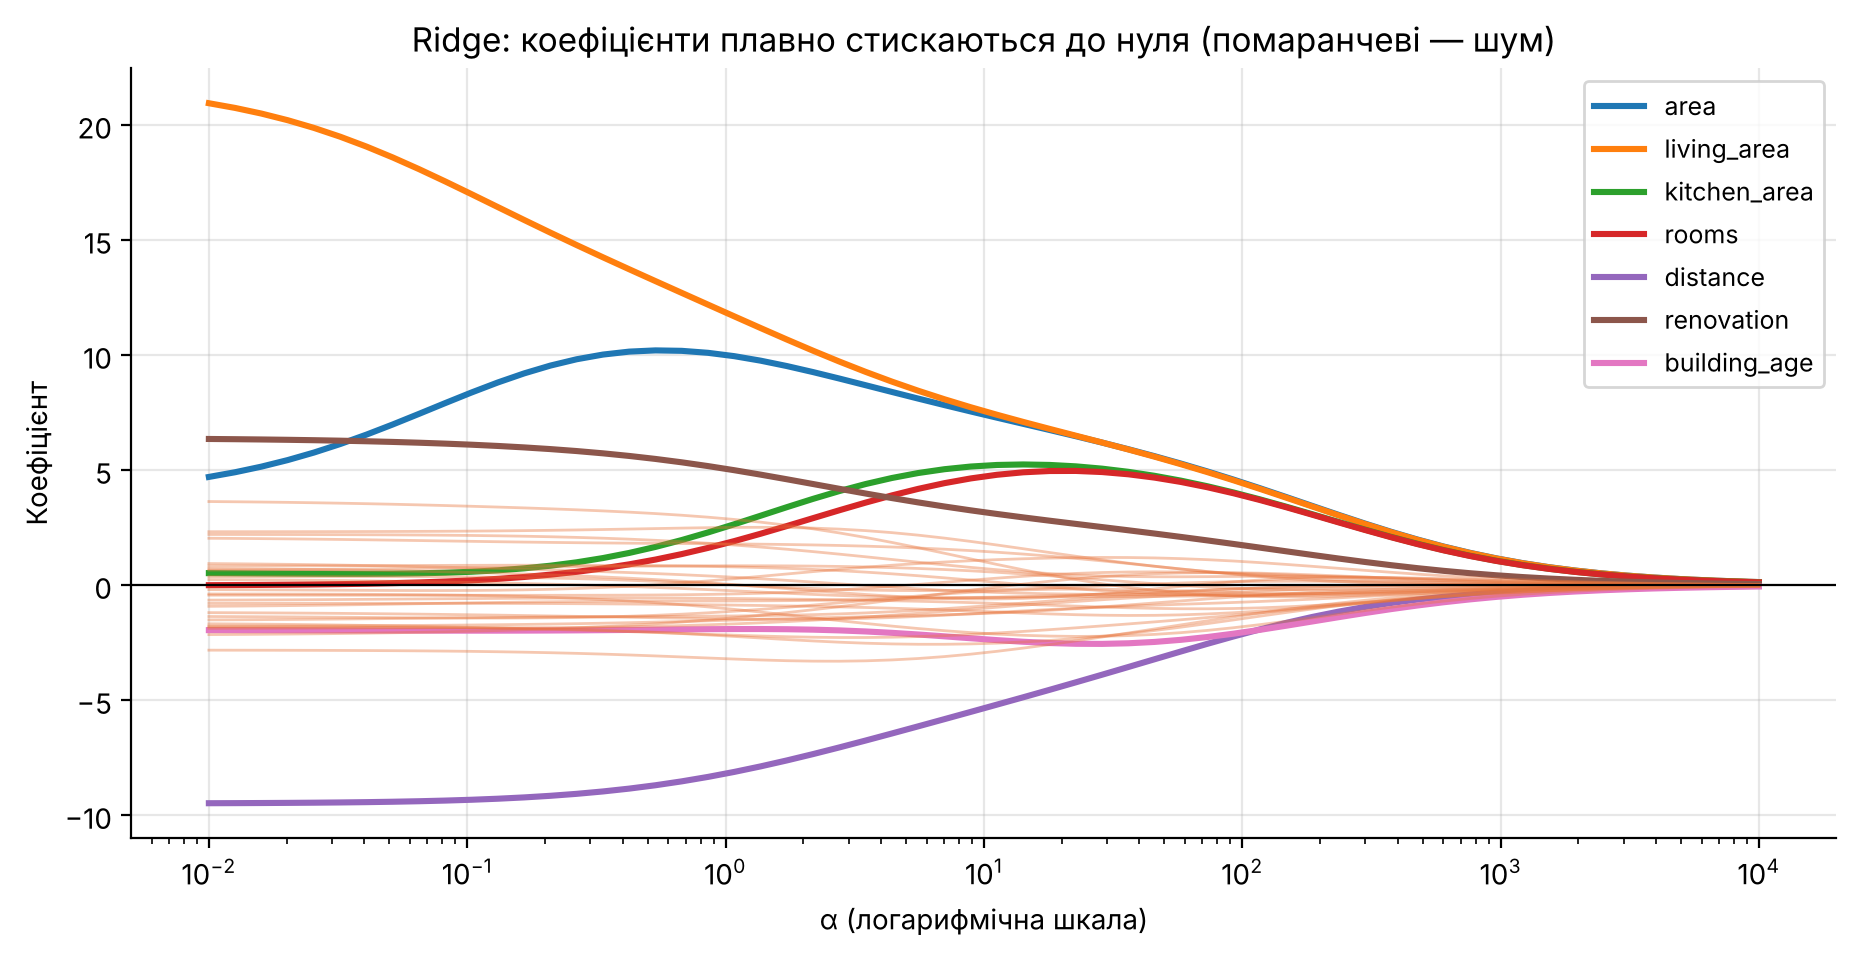

In [ ]:
alphas = np.logspace(-2, 4, 60)        # від 0.01 до 10 000 (логарифмічна шкала)
ridge_path = []
for a in alphas:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    ridge_path.append(m[-1].coef_)
ridge_path = np.array(ridge_path)

plt.figure(figsize=(11, 5))
for j, col in enumerate(X.columns):
    if col.startswith('noise'):
        plt.plot(alphas, ridge_path[:, j], color='#E8743B', alpha=0.4, linewidth=1)
    else:
        plt.plot(alphas, ridge_path[:, j], linewidth=2.2, label=col)
plt.xscale('log')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Ridge: коефіцієнти плавно стискаються до нуля (помаранчеві — шум)')
plt.xlabel('α (логарифмічна шкала)')
plt.ylabel('Коефіцієнт')
plt.legend(fontsize=9, loc='upper right')
plt.show()

**Як читати графік:** зліва (α малий) — коефіцієнти як у звичайної регресії, «розкидані». Зі зростанням α усі лінії **плавно сходяться до нуля**. Шумові (помаранчеві) стискаються першими, бо майже не допомагають, а справжні ознаки «тримаються» довше.

### Ridge і корельовані ознаки

In [ ]:
coef_ridge = pd.Series(ridge[-1].coef_, index=X.columns)
pd.DataFrame({'Звичайна': coef_ols, 'Ridge (α=10)': coef_ridge}).loc[['area', 'living_area', 'kitchen_area', 'distance', 'renovation']].round(2)

,Звичайна,Ridge (α=10)
area,3.810,7.410
living_area,21.830,7.570
kitchen_area,0.560,5.200
distance,-9.490,-5.350
renovation,6.390,3.170


У звичайної регресії майже весь вплив площі «забрала» одна ознака. Ridge розподілив його між трьома «площами» **рівномірніше** (≈ 7.4, 7.6 і 5.2). Такі коефіцієнти стабільніші: на іншій вибірці вони змінились би значно менше. Інтерпретація проста: «більша площа — дорожче».

---
## 5. LASSO-регресія (L1) (⏱ 10 хв)

$$\text{Мінімізуємо:}\quad \text{MSE} + \alpha \sum_{j} \lvert b_j \rvert$$

**Головна відмінність:** через штраф за **модулем** LASSO не просто зменшує коефіцієнти — частину з них він робить **рівно нулем**. Тобто LASSO **сам відбирає ознаки**: те, що отримало 0, модель не використовує.

> Інтуїція: для Ridge (квадрат) маленький коефіцієнт 0.1 «коштує» лише 0.01 — тримати його майже безкоштовно. Для LASSO (модуль) той самий коефіцієнт коштує 0.1 — і якщо ознака приносить менше користі, вигідніше обнулити її повністю.

У sklearn — `Lasso(alpha=...)`. Параметр `max_iter` збільшуємо, щоб алгоритм точно встиг знайти розв'язок.

In [ ]:
lasso = make_pipeline(StandardScaler(), Lasso(alpha=1.5, max_iter=50_000))
lasso.fit(X_train, y_train)

coef_lasso = pd.Series(lasso[-1].coef_, index=X.columns)
kept = coef_lasso[coef_lasso != 0]

print(f'R² train = {r2_score(y_train, lasso.predict(X_train)):.3f} | '
      f'R² test = {r2_score(y_test, lasso.predict(X_test)):.3f} | '
      f'MAE test = {mean_absolute_error(y_test, lasso.predict(X_test)):.2f}')
print(f'\nНенульових коефіцієнтів: {len(kept)} з {len(coef_lasso)}')
print(kept.round(2))

R² train = 0.955 | R² test = 0.937 | MAE test = 6.04

Ненульових коефіцієнтів: 10 з 32
area           18.880
living_area     5.630
rooms           1.950
distance       -7.220
renovation      3.210
building_age   -2.320
noise_18       -0.380
noise_19       -0.140
noise_23       -0.240
noise_24        0.220
dtype: float64


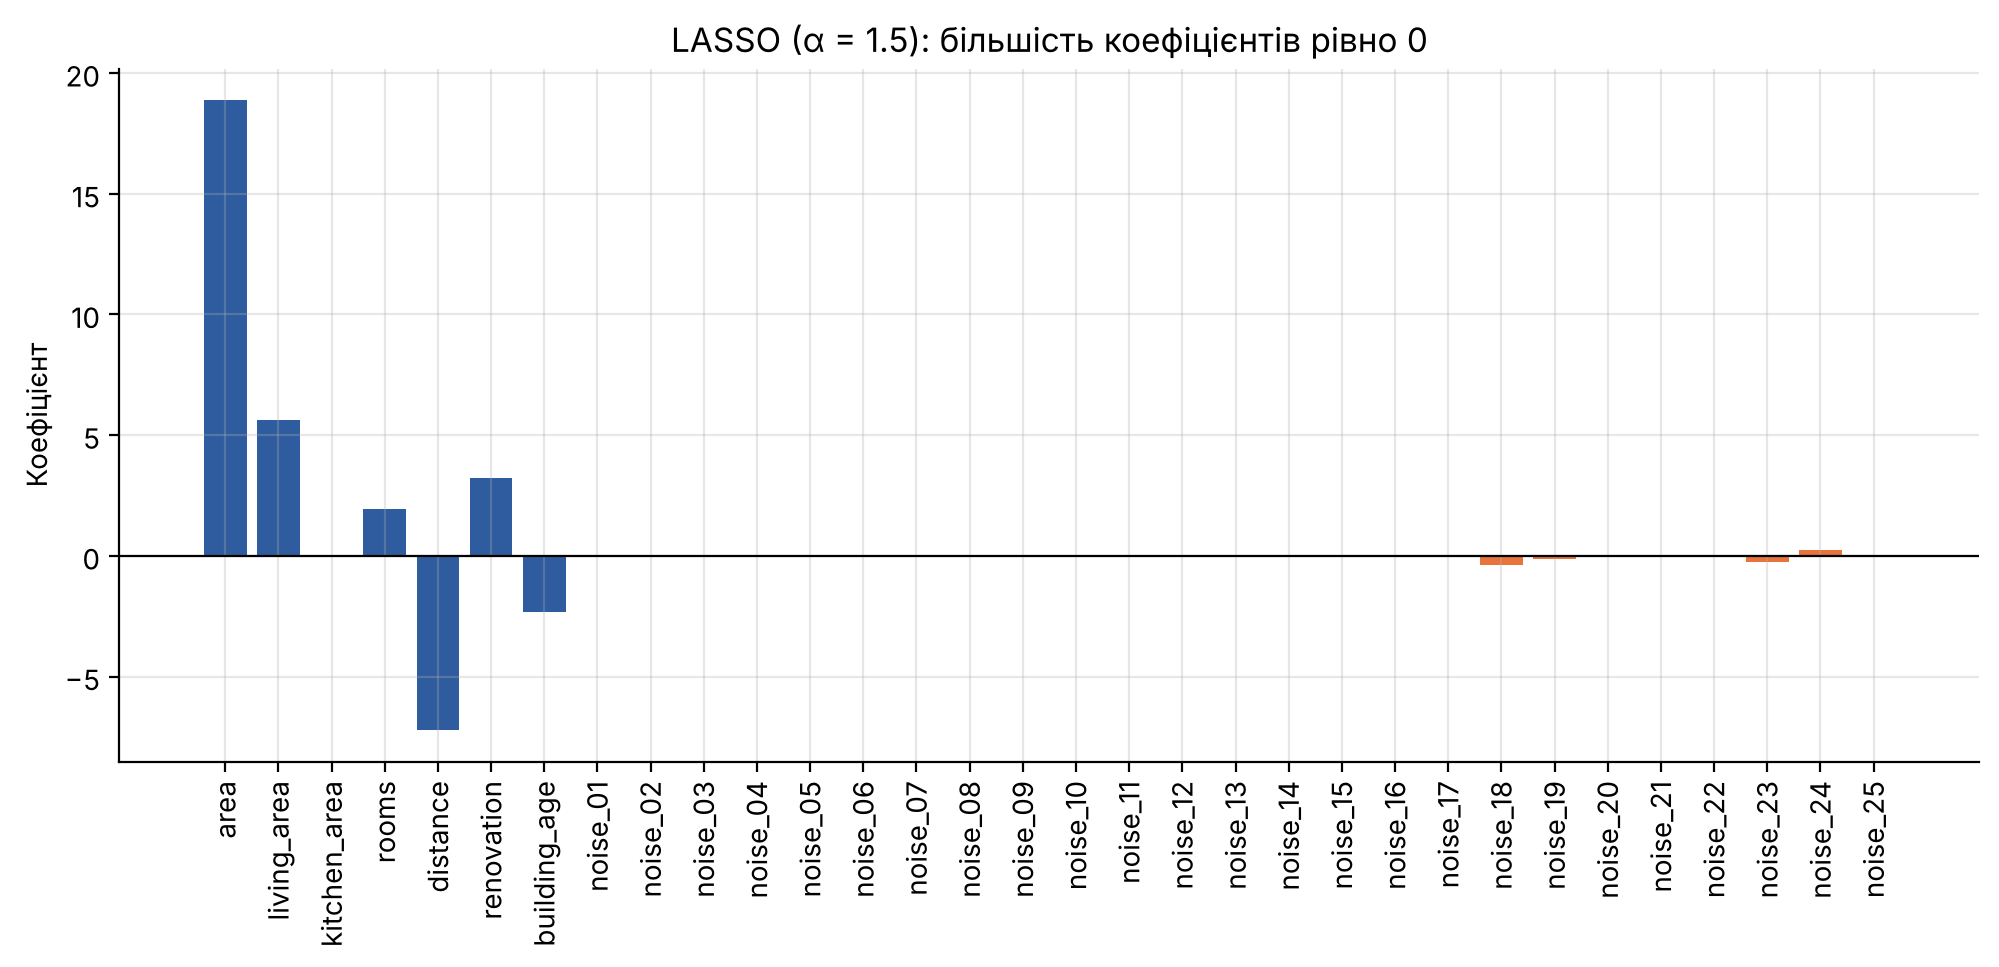

In [ ]:
plt.figure(figsize=(12, 4.5))
plt.bar(X.columns, coef_lasso, color=colors)
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=90)
plt.title('LASSO (α = 1.5): більшість коефіцієнтів рівно 0')
plt.ylabel('Коефіцієнт')
plt.show()

LASSO залишив справжні ознаки і обнулив **більшість** шуму. Кілька шумових ознак вижили з маленькими коефіцієнтами: на 49 квартирах випадкові числа іноді випадково «схожі» на корисні. Що більше α, то жорсткіший відбір.

Ще одна особливість: з трьох «площ» LASSO зазвичай залишає **одну-дві**, а решту обнуляє. Для нього дублікати зайві.

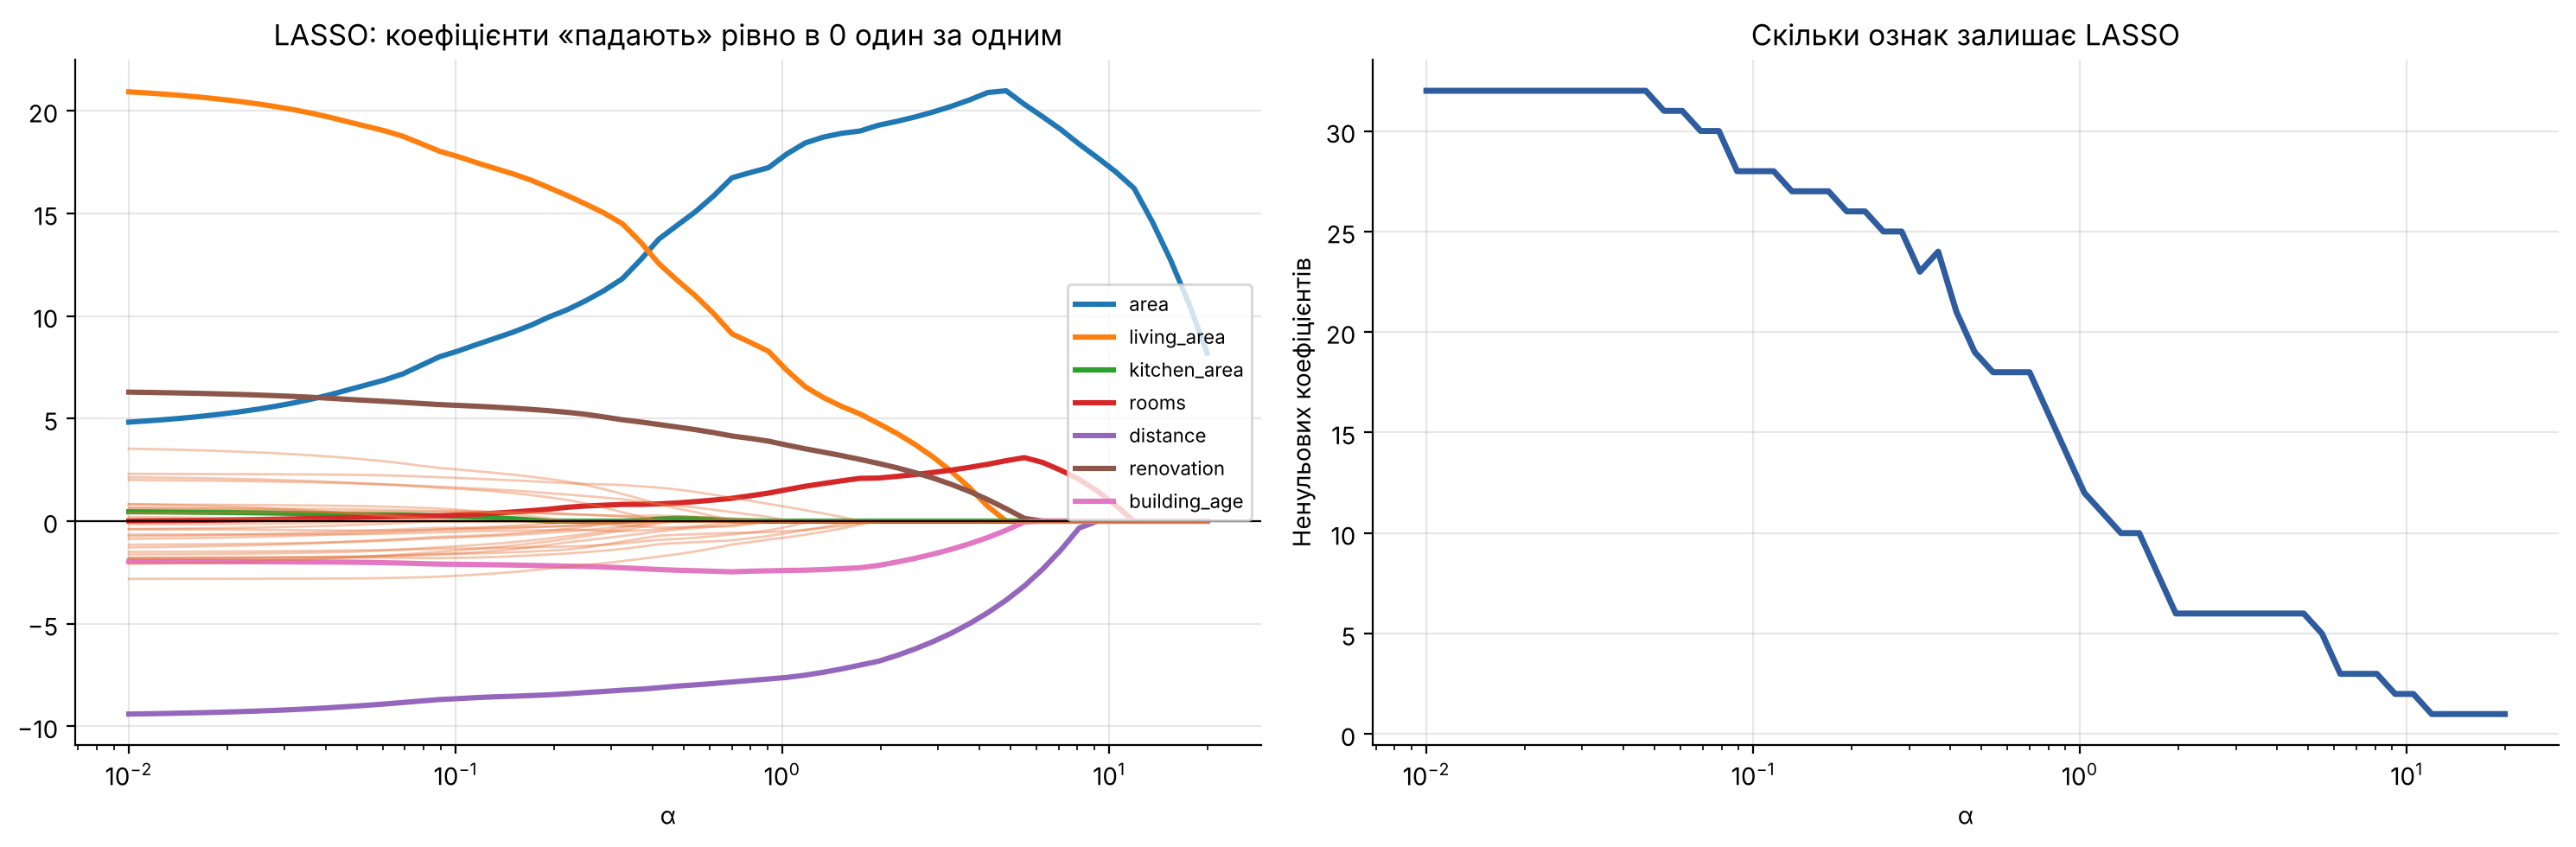

In [ ]:
lasso_path, n_nonzero = [], []
alphas_l = np.logspace(-2, 1.3, 60)        # від 0.01 до ~20
for a in alphas_l:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=50_000)).fit(X_train, y_train)
    lasso_path.append(m[-1].coef_)
    n_nonzero.append((m[-1].coef_ != 0).sum())
lasso_path = np.array(lasso_path)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for j, col in enumerate(X.columns):
    if col.startswith('noise'):
        axes[0].plot(alphas_l, lasso_path[:, j], color='#E8743B', alpha=0.4, linewidth=1)
    else:
        axes[0].plot(alphas_l, lasso_path[:, j], linewidth=2.2, label=col)
axes[0].set_xscale('log')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('LASSO: коефіцієнти «падають» рівно в 0 один за одним')
axes[0].set_xlabel('α')
axes[0].legend(fontsize=8)

axes[1].plot(alphas_l, n_nonzero, color='#2E5C9E', linewidth=2.5)
axes[1].set_xscale('log')
axes[1].set_title('Скільки ознак залишає LASSO')
axes[1].set_xlabel('α')
axes[1].set_ylabel('Ненульових коефіцієнтів')
plt.tight_layout()
plt.show()

**Порівняйте з Ridge:** там лінії плавно наближались до нуля, але не торкались його. Тут вони **впираються в нуль** і там залишаються. Зі зростанням α кількість ознак у моделі падає від 32 до кількох.

🎯 Цікавий факт про наші дані: при α ≈ 5 LASSO залишає **рівно 5 ознак** — і це саме ті 5 справжніх (`area`, `rooms`, `distance`, `renovation`, `building_age`), за якими ми генерували ціну. Усі 25 шумових ознак і обидва «дублікати» площі він відкинув сам. Перевірте це в домашньому завданні 2.

---
## 6. Як обрати силу штрафу α (⏱ 8 хв)

α — гіперпараметр, і від нього сильно залежить результат. Замале α — перенавчання, завелике — недонавчання.

> ⚠️ **Не можна підбирати α за тестовими даними.** Тестова вибірка — «запечатаний конверт» для фінальної оцінки (пам'ятаєте з минулого заняття?). Якщо перебирати α і дивитися на тест, ми «підганяємо» модель під тест.

### Крос-валідація

Ідея: **поділити навчальні дані на 5 частин** (*folds*). П'ять разів навчаємо модель на 4 частинах і перевіряємо на 5-й, щоразу відкладаючи іншу частину. Середня помилка за 5 разів — оцінка якості для цього α. Обираємо α з найменшою помилкою.

```
Раунд 1:  [ПЕРЕВІРКА] [навч.] [навч.] [навч.] [навч.]
Раунд 2:  [навч.] [ПЕРЕВІРКА] [навч.] [навч.] [навч.]
Раунд 3:  [навч.] [навч.] [ПЕРЕВІРКА] [навч.] [навч.]
Раунд 4:  [навч.] [навч.] [навч.] [ПЕРЕВІРКА] [навч.]
Раунд 5:  [навч.] [навч.] [навч.] [навч.] [ПЕРЕВІРКА]
```

Усе це відбувається **всередині train**. Тест залишається недоторканим.

У sklearn це роблять готові класи:
- `RidgeCV(alphas=[...])` — перебирає задані α;
- `LassoCV(cv=5)` — сам підбирає набір α і робить 5-кратну крос-валідацію.

Найкраще α після навчання лежить в атрибуті `.alpha_`.

In [ ]:
ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 50)))
ridge_cv.fit(X_train, y_train)

lasso_cv = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=50_000))
lasso_cv.fit(X_train, y_train)

print(f'Найкраще α для Ridge: {ridge_cv[-1].alpha_:.2f}')
print(f'Найкраще α для LASSO: {lasso_cv[-1].alpha_:.2f}')
print(f'LASSO з найкращим α залишив {(lasso_cv[-1].coef_ != 0).sum()} ознак з {X.shape[1]}')

Найкраще α для Ridge: 9.10
Найкраще α для LASSO: 1.06
LASSO з найкращим α залишив 11 ознак з 32


---
## 7. Ridge проти LASSO: порівняння та інтерпретація (⏱ 10 хв)

### Фінальне порівняння на тестових даних

In [ ]:
models = {'Звичайна регресія': ols, 'Ridge (α з CV)': ridge_cv, 'LASSO (α з CV)': lasso_cv}
rows = []
for name, m in models.items():
    rows.append({'Модель': name,
                 'R² train': r2_score(y_train, m.predict(X_train)),
                 'R² test': r2_score(y_test, m.predict(X_test)),
                 'MAE test, тис. $': mean_absolute_error(y_test, m.predict(X_test)),
                 'Ознак використано': int((np.abs(m[-1].coef_) > 1e-8).sum())})
pd.DataFrame(rows).set_index('Модель')

,R² train,R² test,"MAE test, тис. $",Ознак використано
Модель,,,,
Звичайна регресія,0.985,0.825,10.317,32
Ridge (α з CV),0.972,0.873,7.595,32
LASSO (α з CV),0.963,0.935,6.141,11


Обидві регуляризовані моделі кращі за звичайну на тесті. LASSO тут найкращий: у даних справді багато непотрібних ознак, і він їх прибрав.

### Як інтерпретувати коефіцієнти

Оскільки ми масштабували ознаки, коефіцієнт означає:

> **на скільки зміниться прогноз, якщо ознака зросте на 1 стандартне відхилення** (за інших рівних).

**Плюс:** коефіцієнти тепер **можна порівнювати між собою** — що більший модуль, то сильніший вплив ознаки в моделі.

In [ ]:
coef_table = pd.DataFrame({
    'Звичайна': ols[-1].coef_,
    'Ridge': ridge_cv[-1].coef_,
    'LASSO': lasso_cv[-1].coef_,
}, index=X.columns)

# 7 справжніх ознак + 4 шумові для прикладу
coef_table.loc[['area', 'living_area', 'kitchen_area', 'rooms', 'distance', 'renovation', 'building_age',
                'noise_01', 'noise_02', 'noise_03', 'noise_04']].round(2)

,Звичайна,Ridge,LASSO
area,3.810,7.520,18.040
living_area,21.830,7.700,7.150
kitchen_area,0.560,5.160,0.000
rooms,-0.020,4.660,1.570
distance,-9.490,-5.480,-7.600
renovation,6.390,3.240,3.670
building_age,-1.950,-2.320,-2.400
noise_01,3.680,1.120,0.000
noise_02,0.260,-0.530,0.000
noise_03,2.070,1.500,0.000


**Читаємо таблицю (на прикладі LASSO):**
- **Знак** — напрям: `distance` і `building_age` від'ємні (далі від центру і старіший будинок → дешевше), площа і ремонт додатні.
- **Модуль** — сила: найважливіша ознака — площа (`area`), далі відстань і ремонт.
- **0** — ознака не використовується.

**Перевести в «людські» одиниці:** поділити коефіцієнт на стандартне відхилення ознаки. Наприклад, для відстані:

In [ ]:
sd_distance = X_train['distance'].std(ddof=0)       # StandardScaler використовує ddof=0
b_std = coef_table.loc['distance', 'LASSO']
print(f'Коефіцієнт на масштабованих даних: {b_std:.2f} тис. $ на 1 станд. відхилення ({sd_distance:.1f} км)')
print(f'У звичайних одиницях: {b_std / sd_distance:.2f} тис. $ за кожен кілометр')

Коефіцієнт на масштабованих даних: -7.60 тис. $ на 1 станд. відхилення (3.8 км)
У звичайних одиницях: -2.00 тис. $ за кожен кілометр


### ⚠️ Обережно з інтерпретацією

1. **Регуляризація стискає коефіцієнти**, тож вони трохи менші за модулем, ніж «справжній» ефект. Для прогнозу це добре, але для точного «на скільки зростає ціна» — пам'ятайте про це.
2. **LASSO і корельовані ознаки:** з групи схожих ознак (три «площі») LASSO обирає одну-дві **майже випадково**. Нуль у `living_area` не означає «житлова площа не важлива» — просто цю інформацію вже несе `area`.
3. **Коефіцієнт ≠ причина.** Як і раніше, модель знаходить зв'язки, а не причинність.

### Що обрати?

| Ситуація | Що обрати |
|---|---|
| Багато ознак, більшість **корисні**, багато корельованих | **Ridge** |
| Багато ознак, підозрюємо, що **частина непотрібна**; хочемо просту модель з короткого списку ознак | **LASSO** |
| Хочемо пояснити бізнесу «від чого залежить ціна» коротким списком | **LASSO** |
| Не знаємо | спробувати обидві, порівняти на крос-валідації |

💡 Є ще **ElasticNet** — суміш Ridge і LASSO (`ElasticNet` у sklearn). Корисний, коли є і багато шуму, і групи корельованих ознак.

### Як застосовувати: шаблон

```python
model = make_pipeline(StandardScaler(), LassoCV(cv=5))   # або RidgeCV(alphas=...)
model.fit(X_train, y_train)                              # α підбирається всередині train
print(model[-1].alpha_)                                  # яке α обрано
print(model[-1].coef_)                                   # коефіцієнти (на масштабованих даних)
mean_absolute_error(y_test, model.predict(X_test))       # чесна оцінка на тесті
```

---
# Частина 2. Помилки в коді

## 8. Як читати traceback; типи помилок (⏱ 9 хв)

Коли код «падає», Python друкує **traceback** — звіт про помилку. Новачки часто бачать червоний текст і панікують. Насправді traceback — найкращий помічник: він каже, **що** сталося і **де**.

### Анатомія traceback

Згенеруємо помилку в ланцюжку функцій і виведемо traceback як текст (щоб ноутбук не зупинявся).

In [ ]:
import traceback

def price_per_m2(price, area):
    return price / area

def flat_report(flat):
    ppm = price_per_m2(flat['price'], flat['area'])
    return f'Ціна за м²: {ppm:.2f} тис. $'

flat = {'price': 80, 'area': 0}      # помилка в даних: площа 0

try:
    flat_report(flat)
except Exception:
    print(traceback.format_exc())

Traceback (most recent call last):
  File "/tmp/ipykernel_326/3425953372.py", line 13, in <module>
    flat_report(flat)
    ~~~~~~~~~~~^^^^^^
  File "/tmp/ipykernel_326/3425953372.py", line 7, in flat_report
    ppm = price_per_m2(flat['price'], flat['area'])
  File "/tmp/ipykernel_326/3425953372.py", line 4, in price_per_m2
    return price / area
           ~~~~~~^~~~~~
ZeroDivisionError: division by zero



**Читаємо знизу вгору:**

| Частина | Що в ній | Тут |
|---|---|---|
| **Останній рядок** ⬇️ | **тип помилки** і **повідомлення** — найважливіше! | `ZeroDivisionError: division by zero` — ділення на нуль |
| Рядок над ним | **де саме** сталося: файл, номер рядка, функція і сам код. Значки `~~~^~~~` під кодом підкреслюють точне місце | у функції `price_per_m2`, рядок `return price / area` |
| Вище | **як ми туди потрапили**: хто кого викликав | `flat_report` викликала `price_per_m2` |
| Перший рядок | `Traceback (most recent call last):` — «останній виклик — унизу» | |

> 💡 **Правило:** спершу читайте **останній рядок** (що сталося), потім рядок над ним (де). У 90% випадків цього достатньо, щоб знайти проблему. У Colab шлях до файлу виглядатиме інакше (`<ipython-input-...>`), але структура та сама.

Тут помилка не в коді функції, а в **даних** (площа 0). Traceback показує, де «вибухнуло», а причина може бути вище, тому дивіться на всі рядки.

### Найчастіші типи помилок

| Помилка | Що означає | Типовий приклад |
|---|---|---|
| `SyntaxError` | код написано з порушенням правил мови | пропущена дужка, лапка, двокрапка |
| `NameError` | змінна чи функція не існує | друкарська помилка в назві; забули запустити клітинку вище |
| `TypeError` | операція не підходить для цього типу даних | `'Ціна: ' + 100` (рядок + число) |
| `ValueError` | тип правильний, а значення — ні | `int('сто')`; X має неправильну форму для sklearn |
| `KeyError` | немає такого ключа в словнику / колонки в DataFrame | `df['prise']` замість `df['price']` |
| `IndexError` | індекс за межами списку | `lst[5]`, коли в списку 3 елементи |
| `AttributeError` | в об'єкта немає такого методу чи атрибута | `'текст'.mean()` |
| `ZeroDivisionError` | ділення на нуль | `80 / 0` |
| `ModuleNotFoundError` | бібліотеку не встановлено або назву написано з помилкою | `import sklearn_magic` |

In [ ]:
examples = [
    "print(revenu)",                # друкарська помилка в назві
    "'Ціна: ' + 100",
    "int('сто')",
    "{'price': 80}['area']",
    "[1, 2, 3][5]",
    "'текст'.mean()",
    "80 / 0",
    "import sklearn_magic",
    "print('привіт'",               # пропущена дужка
]
for snippet in examples:
    try:
        exec(snippet)
    except Exception as e:
        print(f'{snippet:24} → {type(e).__name__}: {e}')

print(revenu)            → NameError: name 'revenu' is not defined
'Ціна: ' + 100           → TypeError: can only concatenate str (not "int") to str
int('сто')               → ValueError: invalid literal for int() with base 10: 'сто'
{'price': 80}['area']    → KeyError: 'area'
[1, 2, 3][5]             → IndexError: list index out of range
'текст'.mean()           → AttributeError: 'str' object has no attribute 'mean'
80 / 0                   → ZeroDivisionError: division by zero
import sklearn_magic     → ModuleNotFoundError: No module named 'sklearn_magic'
print('привіт'           → SyntaxError: '(' was never closed (<string>, line 1)


### Типові помилки зі sklearn

In [ ]:
sklearn_examples = {
    'X — одинарні дужки (вектор замість таблиці)': lambda: LinearRegression().fit(X_train['area'], y_train),
    'predict до fit': lambda: Ridge().predict(X_test),
    'на прогнозі не ті колонки': lambda: ridge.predict(X_test[['area', 'rooms']]),
    'різна кількість рядків у X і y': lambda: Ridge().fit(X_train, y_test),
}
for label, func in sklearn_examples.items():
    try:
        func()
    except Exception as e:
        print(f'▶ {label}\n  {type(e).__name__}: {str(e)[:140]}\n')

▶ X — одинарні дужки (вектор замість таблиці)
  ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or

▶ predict до fit
  NotFittedError: This Ridge instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

▶ на прогнозі не ті колонки
  ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- building_age
- distance

▶ різна кількість рядків у X і y
  ValueError: Found input variables with inconsistent numbers of samples: [49, 21]



### Що робити, коли бачите помилку

1. **Прочитайте останній рядок**: тип і повідомлення.
2. **Знайдіть рядок коду**, на який вказує traceback.
3. **Перевірте дані** в цьому місці: `print(...)`, `.shape`, `.head()`, `type(...)`.
4. Не зрозуміло? **Скопіюйте останній рядок** у пошук. З цією помилкою вже стикалися тисячі людей.

---
## 9. `assert` і навіщо він потрібен (⏱ 8 хв)

`assert` — це **перевірка припущення** в коді:

```python
assert умова, 'повідомлення, якщо умова хибна'
```

- Якщо умова **правдива** — нічого не відбувається, код іде далі.
- Якщо **хибна** — програма зупиняється з помилкою `AssertionError` і вашим повідомленням.

### Навіщо, якщо Python і так видає помилки?

Бо **найнебезпечніші помилки в аналітиці — ті, що не «падають»**. Наприклад:
- у даних з'явились пропуски, і модель тихо навчилась на сміттєвих значеннях;
- після злиття таблиць рядків стало вдвічі більше, але код працює;
- train і test випадково перетинаються, і метрики красиво завищені.

Код не видасть жодної помилки — просто результати будуть **неправильні**. `assert` перетворює такі «тихі» проблеми на **гучні**: програма зупиняється одразу, з поясненням.

> 💡 Думайте про `assert` як про **запобіжник**: «я впевнений, що тут має бути так. Якщо ні — зупинись і скажи мені».

In [ ]:
# Перевірки, які варто робити перед навчанням моделі
assert X_train.shape[0] == y_train.shape[0], 'Різна кількість рядків у X_train і y_train'
assert not X_train.isna().any().any(), 'У навчальних даних є пропуски'
assert set(X_train.index).isdisjoint(X_test.index), 'Train і test перетинаються!'
assert (y_train > 0).all(), 'Ціна має бути додатною'
print('✅ Усі перевірки пройдено')

✅ Усі перевірки пройдено


In [ ]:
# Що буде, якщо перевірка не пройде? Додамо пропуск і перевіримо (через try, щоб ноутбук не зупинявся)
broken = X_train.copy()
broken.iloc[3, 0] = np.nan

try:
    assert not broken.isna().any().any(), f'У даних є пропуски: {int(broken.isna().sum().sum())} шт.'
except AssertionError as e:
    print('AssertionError:', e)

AssertionError: У даних є пропуски: 1 шт.


### `assert` у власних функціях

Функція перевіряє свої вхідні дані — і повідомляє **зрозумілою мовою**, що не так, замість загадкової помилки десь глибоко в sklearn.

In [ ]:
def train_ridge(X, y, alpha):
    assert alpha >= 0, f'alpha має бути ≥ 0, а отримано {alpha}'
    assert len(X) == len(y), f'X має {len(X)} рядків, а y — {len(y)}'
    assert not X.isna().any().any(), 'У X є пропуски — заповніть або видаліть їх'
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X, y)

for args in [(X_train, y_train, 10), (X_train, y_train, -5), (X_train, y_test, 10)]:
    try:
        train_ridge(*args)
        print('✅ Модель навчено')
    except AssertionError as e:
        print('❌ AssertionError:', e)

✅ Модель навчено
❌ AssertionError: alpha має бути ≥ 0, а отримано -5
❌ AssertionError: X має 49 рядків, а y — 21


### Правила використання

| ✅ Використовуйте `assert` для | ❌ Не використовуйте `assert` для |
|---|---|
| перевірки **власних припущень** про дані й код (форми, пропуски, діапазони) | перевірки того, що вводить **користувач** у програму |
| «санітарних» перевірок у ноутбуках і пайплайнах | обробки очікуваних ситуацій (для цього — `if` і `raise ValueError`) |

Чому так: Python можна запустити з прапорцем `-O`, і тоді **усі `assert` вимикаються**. Тож на них не можна покладатися як на захист у робочій програмі — це інструмент **розробника й аналітика**.

---
## 10. 🧾 Підсумок (⏱ 3 хв)

| | Звичайна регресія | **Ridge** | **LASSO** |
|---|---|---|---|
| Що мінімізує | MSE | MSE + α·Σb² | MSE + α·Σ\|b\| |
| Коефіцієнти | будь-які, можуть бути «дикими» | стиснуті, **не нульові** | стиснуті, **частина = 0** |
| Відбір ознак | ні | ні | **так** |
| Корельовані ознаки | нестабільні коефіцієнти | розподіляє вплив рівномірно | залишає одну з групи |
| Масштабування | бажано | **обов'язково** | **обов'язково** |
| sklearn | `LinearRegression()` | `Ridge(alpha)`, `RidgeCV` | `Lasso(alpha)`, `LassoCV` |

### 5 речей, які варто запам'ятати

1. **Багато ознак + мало даних = перенавчання.** Регуляризація — штраф за великі коефіцієнти — це виправляє.
2. **Ridge стискає всі коефіцієнти, LASSO частину обнуляє** (і так відбирає ознаки).
3. **Завжди масштабуйте ознаки** (`StandardScaler` у `Pipeline`), scaler навчайте лише на train.
4. **α підбирайте крос-валідацією** (`RidgeCV`, `LassoCV`), а не за тестом.
5. **Traceback читаємо знизу вгору; `assert` перетворює «тихі» помилки в даних на гучні.**

---
## ✍️ Перевірте себе (домашнє завдання)

Під кожним завданням — порожня клітинка для коду.

**Завдання 1.** Навчіть `Ridge` з α = 0.1, 10 і 1000 (з масштабуванням). Для кожного α виведіть R² на train і test. Поясніть, що відбувається при дуже великому α.

In [ ]:
# Ваш код тут

**Завдання 2.** Навчіть `Lasso` з α = 0.5, 2 і 5. Скільки ненульових коефіцієнтів залишається в кожному випадку? Які ознаки «виживають» при α = 5?

In [ ]:
# Ваш код тут

**Завдання 3.** Наступний код падає. Прочитайте traceback, назвіть тип помилки і виправте:

```python
model = make_pipeline(StandardScaler(), Lasso(alpha=1))
model.fit(X_train[['area', 'distance']], y_train)
model.predict(X_test[['area', 'distanse']])
```

In [ ]:
# Ваш код тут

**Завдання 4.** Напишіть функцію `check_split(X_train, X_test, y_train, y_test)`, яка через `assert` перевіряє: однакова кількість рядків у X і y (окремо для train і test), однакові колонки в X_train і X_test, немає пропусків. Перевірте її на наших даних.

In [ ]:
# Ваш код тут

---
## 🔑 Розв'язки (для викладача)

In [ ]:
# Завдання 1
for a in [0.1, 10, 1000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    print(f'α = {a:>6}: R² train = {r2_score(y_train, m.predict(X_train)):.3f} | R² test = {r2_score(y_test, m.predict(X_test)):.3f}')
# При α = 1000 коефіцієнти стиснуті майже до нуля → модель занадто проста (недонавчання), R² падає і на train, і на test.

α =    0.1: R² train = 0.985 | R² test = 0.833
α =     10: R² train = 0.971 | R² test = 0.874
α =   1000: R² train = 0.298 | R² test = 0.221


In [ ]:
# Завдання 2
for a in [0.5, 2, 5]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=50_000)).fit(X_train, y_train)
    nz = pd.Series(m[-1].coef_, index=X.columns)
    nz = nz[nz != 0]
    print(f'α = {a}: {len(nz)} ознак → {list(nz.index)}')

α = 0.5: 18 ознак → ['area', 'living_area', 'kitchen_area', 'rooms', 'distance', 'renovation', 'building_age', 'noise_01', 'noise_03', 'noise_08', 'noise_09', 'noise_18', 'noise_19', 'noise_20', 'noise_21', 'noise_22', 'noise_23', 'noise_24']
α = 2: 6 ознак → ['area', 'living_area', 'rooms', 'distance', 'renovation', 'building_age']
α = 5: 5 ознак → ['area', 'rooms', 'distance', 'renovation', 'building_age']


In [ ]:
# Завдання 3: KeyError — колонки 'distanse' немає (друкарська помилка). Виправлення:
model = make_pipeline(StandardScaler(), Lasso(alpha=1))
model.fit(X_train[['area', 'distance']], y_train)
print(model.predict(X_test[['area', 'distance']])[:5])

[ 95.95631582 130.75629027  55.39440983  97.58965549 103.052831  ]


In [ ]:
# Завдання 4
def check_split(X_train, X_test, y_train, y_test):
    assert len(X_train) == len(y_train), 'Train: різна кількість рядків у X і y'
    assert len(X_test) == len(y_test), 'Test: різна кількість рядків у X і y'
    assert list(X_train.columns) == list(X_test.columns), 'Різні колонки в train і test'
    assert not X_train.isna().any().any() and not X_test.isna().any().any(), 'Є пропуски'
    print('✅ Розбиття коректне')

check_split(X_train, X_test, y_train, y_test)

✅ Розбиття коректне
